Installing package into 'C:/Users/yoser/AppData/Local/R/win-library/4.6'
(as 'lib' is unspecified)



package 'ACSWR' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\yoser\AppData\Local\Temp\Rtmpm2XzI1\downloaded_packages
'data.frame':	16 obs. of  3 variables:
 $ Tip_Type   : int  1 1 1 1 2 2 2 2 3 3 ...
 $ Test_Coupon: int  1 2 3 4 1 2 3 4 1 2 ...
 $ Hardness   : num  9.3 9.4 9.6 10 9.4 9.3 9.8 9.9 9.2 9.4 ...


,Tip_Type,Test_Coupon,Hardness
,<int>,<int>,<dbl>
1,1,1,9.3
2,1,2,9.4
3,1,3,9.6
4,1,4,10.0
5,2,1,9.4
6,2,2,9.3


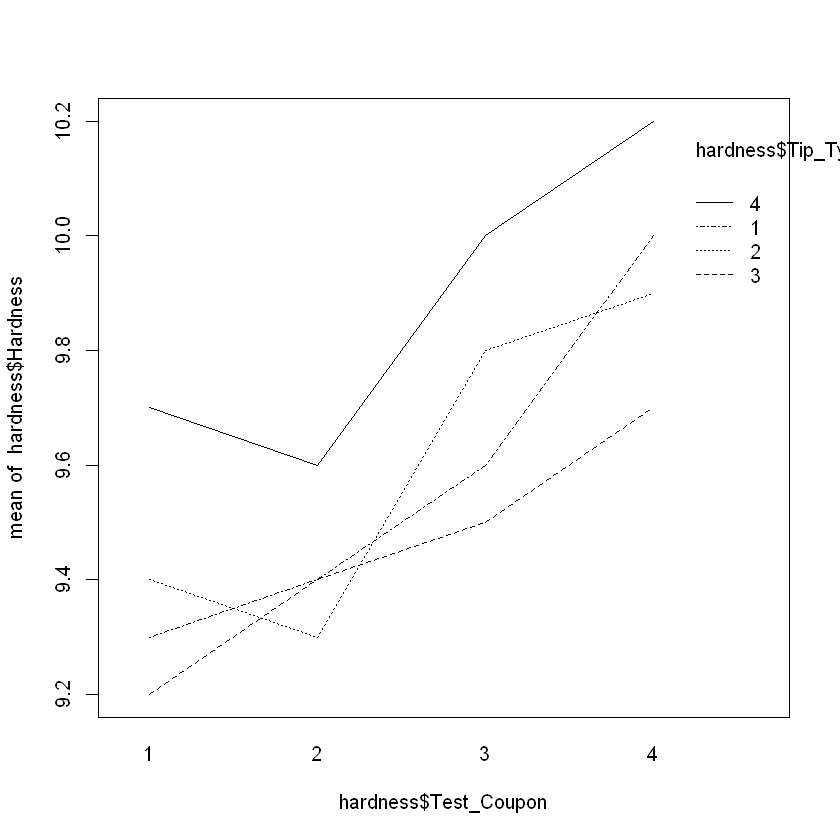

In [3]:
install.packages("ACSWR")
library(ACSWR)
# cargamos el conjunto de datos hardness
data(hardness)
# exploramos el conjunto de datos
str(hardness)
# vemos la composición de los datos de hardness
head(hardness)
# Análisis Visual mediante el Diagrama de Interación
interaction.plot(hardness$Test_Coupon,
                hardness$Tip_Type,
                hardness$Hardness)

# Parte I

## Fase 1
El grafico muestra en el eje $x$ el grupo del cupon de prueba y en el eje $y$, la media de la variable de respuesta, la dureza del cupon. Los tipos de punta se diferencian por la forma de la linea. El gráfico muestra cómo varía la dureza del metal (Hardness) según el tipo de punta (Tip_Type) y el cupón de prueba (Test_Coupon).

### a. Cada tipo de punta
- Punta 4 (linea sólida): produce en general las mayores lecturas de dureza.
- Punta 1 (linea semipunteada): presenta una tendencia creciente en la dureza. Se puede observar que es la que crece a mayor velocidad dependiendo del cupón de prueba, empieza con el menor valor y termina con el segundo mayor.
- Punta 2 (linea punteada): presenta una disminución en la dureza entre los cupones 1 y 2, pero con un crecimiento pronunciado en los cupones 2 y 3, disminuyendo la tasa de crecimiento en el cupón 4.
- Punta 3 (linea con guiones): Presenta un el crecimiento más lento en la dureza, con lecturas que se mantienen relativamente estables entre los cupones 1, 2 y 3. Presenta valores generalmente bajos.

En general, se pueden observar diferencias en la dureza según el tipo de punta. 


### b. Cada cupon
- Cupón 1: Se presenta cierta variabilidad en la dureza según el tipo de punta, con la punta 4 mostrando la mayor dureza y la punta 3 la menor.
- Cupón 2: Se puede observar una menor dispersión en la dureza entre los tipos de punta
- Cupón 3: La dureza aumenta para todas las puntas, con la punta 4 manteniendo la mayor dureza y la punta 3 la menor.
- Cupón 4: Presenta un aumento en la dureza para todas las puntas, con la punta 4 manteniendo la mayor dureza y la punta 3 la menor.

Se puede observar una tendencia general de aumento en la dureza entre los cupones 1 y 4, en orden de menor a mayor. Esto sugiere que los cupones pueden presentar diferencias en su dureza, independientemente del tipo de punta utilizado.


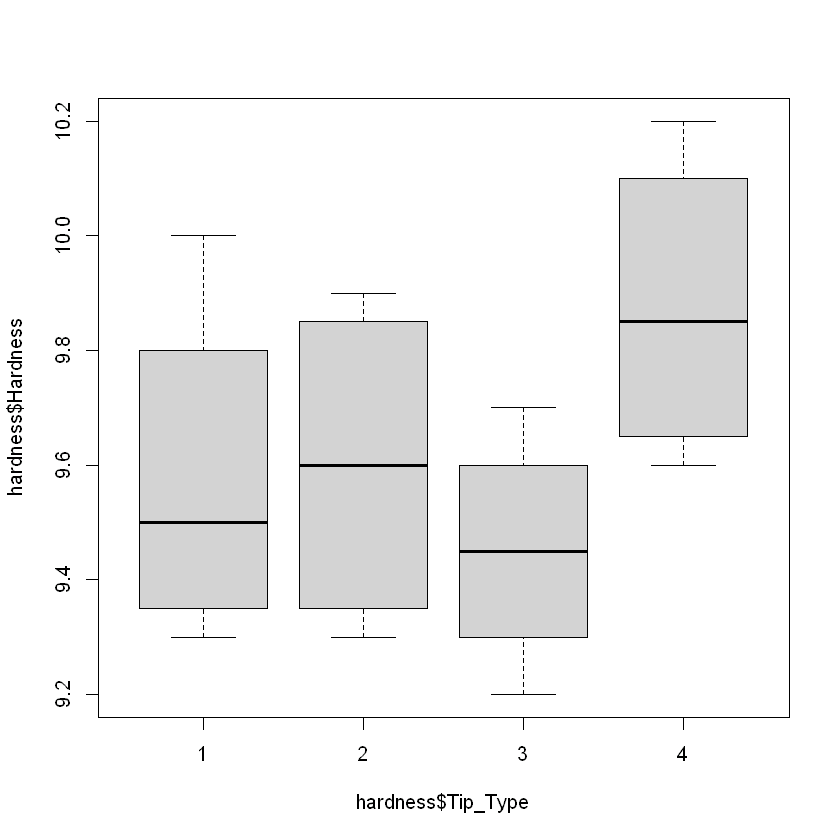

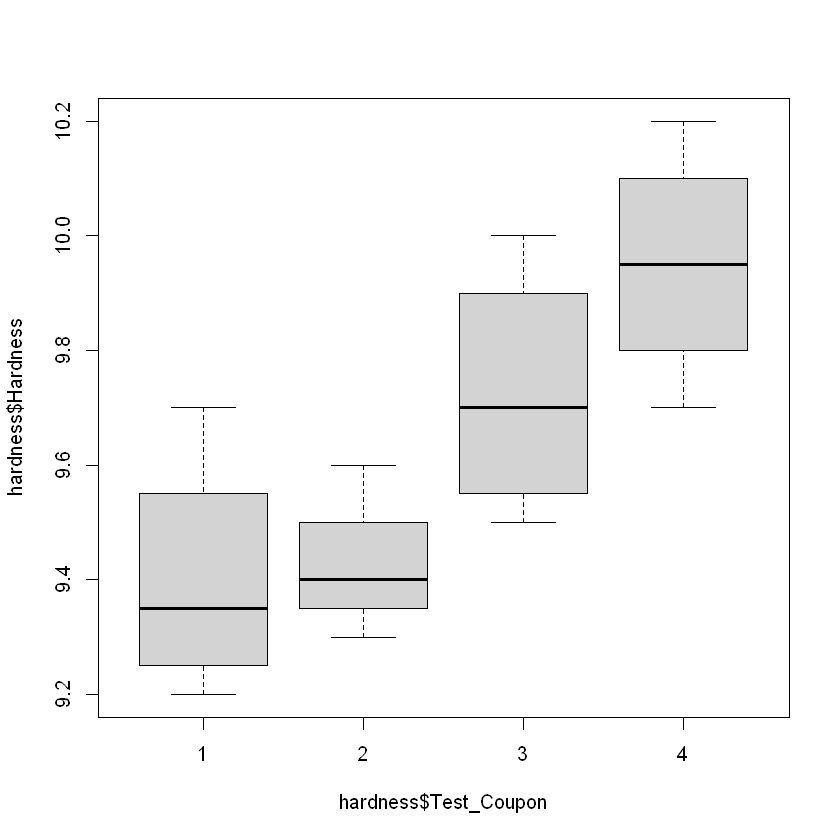

In [4]:
boxplot(hardness$Hardness ~ hardness$Tip_Type)
boxplot(hardness$Hardness ~ hardness$Test_Coupon)

## Fase 2
### 1
### 2 

In [5]:
anova(aov(hardness$Hardness ~ factor(hardness$Tip_Type) +
factor(hardness$Test_Coupon)))
fit <- aov(hardness$Hardness ~ factor(hardness$Tip_Type) + factor(hardness$Test_Coupon))
TukeyHSD(fit,
which= "factor(hardness$Tip_Type)",
ordered=TRUE)

summary(aov(hardness$Hardness ~ factor(hardness$Tip_Type) +
factor(hardness$Test_Coupon)))

,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
factor(hardness$Tip_Type),3,0.385,0.128333333,14.4375,0.0008712721
factor(hardness$Test_Coupon),3,0.825,0.275000000,30.9375,0.0000452327
Residuals,9,0.080,0.008888889,NA,NA


  Tukey multiple comparisons of means
    95% family-wise confidence level
    factor levels have been ordered

Fit: aov(formula = hardness$Hardness ~ factor(hardness$Tip_Type) + factor(hardness$Test_Coupon))

$`factor(hardness$Tip_Type)`
     diff         lwr       upr     p adj
1-3 0.125 -0.08311992 0.3331199 0.3027563
2-3 0.150 -0.05811992 0.3581199 0.1815907
4-3 0.425  0.21688008 0.6331199 0.0006061
2-1 0.025 -0.18311992 0.2331199 0.9809005
4-1 0.300  0.09188008 0.5081199 0.0066583
4-2 0.275  0.06688008 0.4831199 0.0113284


                             Df Sum Sq Mean Sq F value   Pr(>F)    
factor(hardness$Tip_Type)     3  0.385 0.12833   14.44 0.000871 ***
factor(hardness$Test_Coupon)  3  0.825 0.27500   30.94 4.52e-05 ***
Residuals                     9  0.080 0.00889                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

## Fase 3
### 1
### 2


Call:
lm(formula = hardness$Hardness ~ factor(hardness$Tip_Type) + 
    factor(hardness$Test_Coupon))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.10000 -0.05625 -0.01250  0.03125  0.15000 

Coefficients:
                              Estimate Std. Error t value Pr(>|t|)    
(Intercept)                    9.35000    0.06236 149.934  < 2e-16 ***
factor(hardness$Tip_Type)2     0.02500    0.06667   0.375 0.716345    
factor(hardness$Tip_Type)3    -0.12500    0.06667  -1.875 0.093550 .  
factor(hardness$Tip_Type)4     0.30000    0.06667   4.500 0.001489 ** 
factor(hardness$Test_Coupon)2  0.02500    0.06667   0.375 0.716345    
factor(hardness$Test_Coupon)3  0.32500    0.06667   4.875 0.000877 ***
factor(hardness$Test_Coupon)4  0.55000    0.06667   8.250 1.73e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.09428 on 9 degrees of freedom
Multiple R-squared:  0.938,	Adjusted R-squared:  0.8966 
F-statistic: 22.69 on 6 and 

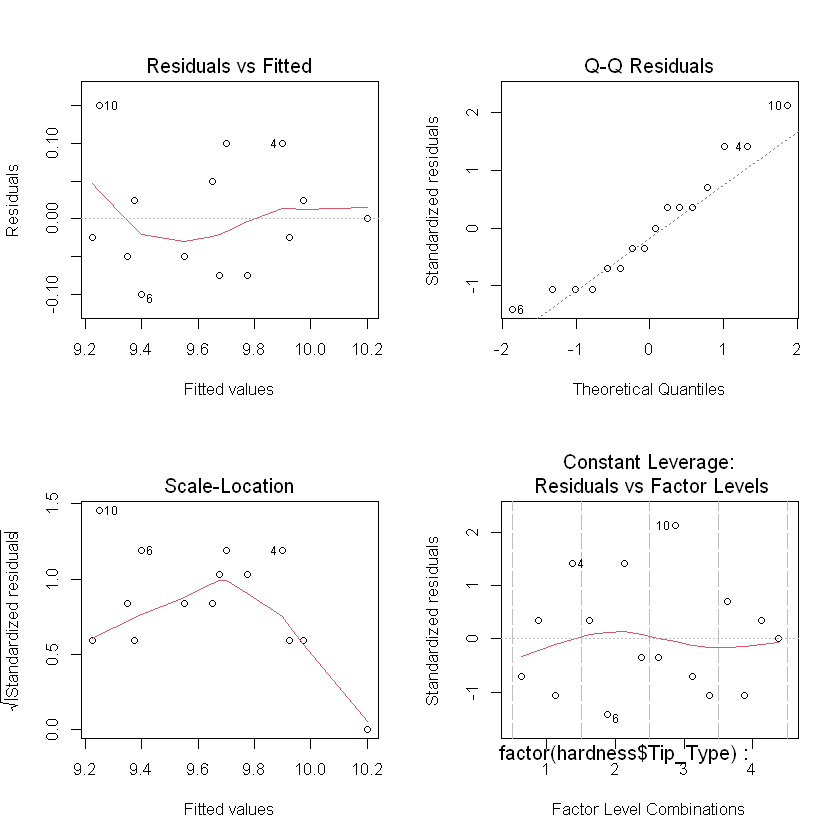

In [7]:
summary(lm(hardness$Hardness ~ factor(hardness$Tip_Type) +
factor(hardness$Test_Coupon)))

par(mfrow=c(2,2),
bg = "white",
  fg = "black",
  col.axis = "black",
  col.lab = "black",
  col.main = "black")
plot(lm(hardness$Hardness ~ factor(hardness$Tip_Type) + factor(hardness$Test_Coupon)))

## Fase 4

### 1. En el gráfico Fitted Values vs Residuals, observamos que no existe un patrón definido, esto es esperado porque existe independencia estadística entre los residuales (un residual no depende del otro). Explique porque espera usted que esto sea algo esperado y adecuado en un conjunto de datos normalmente distribuido.
Es esperado que no haya un patrón, porque si lo hay, significaría que el modelo no está logrando explicar algo del comportamiento de los datos. Por ejemplo, si hubiese una tendencia positiva o negativa gradual en los residuos, sería preocupante porque surgiere que el modelo está ignorando algún tipo de relación importante. Es adecuado que los residuos estén dispersos, estén cerca del 0 y ser pequeños, porque en un conjunto de datos normal, se sigue la forma de la campana de Gauss, y como están centrados en 0, los residuos también se acercan al 0, teniendo valores tanto negativos como positivos. Eso sí, un conjunto de datos normal no significa necesariamente que los residuos son independientes.

### 2. En el gráfico del segundo pánel (derecha) se observa la aproximación a la distribución normal. Describa que tanto se aproxima este conjunto a la normal. ¿Puede usted decir que este conjunto esta normalmente distribuido? ¿Existe alguna prueba más que le pueda ayudar a verificar esto? 
Según el Q-Q, los residuos parecen sí tener normalidad. Se puede observar que los datos siguen la forma y están muy cerca de la línea de normalidad. Sin embargo, sólo con el gráfico no se puede asegurar nada, si no, que se debe aplicar una prueba estadística para comprobarlo. Se puede usar la de Shapiro-Wilk si son pocos datos, como en este caso. En casos con más datos, se podría usar la Liliefors.

### 3. En la esquina inferior derecha se observa la distribución estandarizada de los residuales contrastada con los niveles de factor (Puntas). Comente con base en lo que se ha discutido en clase que puede interpetar usted con respecto a la distribución de esta distribución (es homogénea o heterogénea), y si esta es adecuado o inadecuada.
Se puede observar que puntas 1 y 2 se ven bastante disperas y similares entre ellas. Punta 3 se mantiene en los valores negativos, mientras que punta 4 tiene valores positivos y parece tener variabilidad, aunque no tan amplia como la de puntas 1 y 2. Con el gráfico se puede notar que podría llegar a ser homogénea, aunque punta 3 no se vea tan dispera. La interpretación es válida, pero no adecuada como para confirmar solo con este gráfico si existe homogeneidad o no, ya que se ocupa aplicar alguna prueba como la de Levene.

# Parte II

In [6]:
library(ACSWR)
data("intensity")
intensity

Intensity,Operator,Filter,Ground
<dbl>,<fct>,<fct>,<fct>
90,1,1,low
102,1,1,medium
114,1,1,high
86,1,2,low
87,1,2,medium
93,1,2,high
96,2,1,low
106,2,1,medium
112,2,1,high


# Pendiente de reunión